# MLT Task 1
Natalya Makushkina

# Training classifiers

In [116]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [117]:
df = pd.read_csv("bioresponse.csv", header=0)
display(df.head())
display(df.shape)

nan_counts = df.isna().sum()
display(nan_counts[nan_counts > 0])

df['Activity'].value_counts()


,Activity,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,D1767,D1768,D1769,D1770,D1771,D1772,D1773,D1774,D1775,D1776
0,1,0.000000,0.497009,0.10,0.0,0.132956,0.678031,0.273166,0.585445,0.743663,...,0,0,0,0,0,0,0,0,0,0
1,1,0.366667,0.606291,0.05,0.0,0.111209,0.803455,0.106105,0.411754,0.836582,...,1,1,1,1,0,1,0,0,1,0
2,1,0.033300,0.480124,0.00,0.0,0.209791,0.610350,0.356453,0.517720,0.679051,...,0,0,0,0,0,0,0,0,0,0
3,1,0.000000,0.538825,0.00,0.5,0.196344,0.724230,0.235606,0.288764,0.805110,...,0,0,0,0,0,0,0,0,0,0
4,0,0.100000,0.517794,0.00,0.0,0.494734,0.781422,0.154361,0.303809,0.812646,...,0,0,0,0,0,0,0,0,0,0


(3751, 1777)

Series([], dtype: int64)

Activity
1    2034
0    1717
Name: count, dtype: int64

In [118]:
bioresponce_target = df.Activity.values
bioresponce_data = df.iloc[:, 1:]
display(bioresponce_target.shape)
display(bioresponce_data.shape)


(3751,)

(3751, 1776)

In [119]:
X_train, X_test, y_train, y_test = train_test_split(bioresponce_data, bioresponce_target, test_size=0.25, random_state=42, stratify=bioresponce_target)
display(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(2813, 1776)

(2813,)

(938, 1776)

(938,)

In [120]:
small_tree = DecisionTreeClassifier(max_depth=5, random_state=42)
small_tree.fit(X_train, y_train)

deep_tree = DecisionTreeClassifier(max_depth=10, random_state=42)
deep_tree.fit(X_train, y_train)

small_forest = RandomForestClassifier(max_depth=5, random_state=42, n_estimators=50, criterion='gini')
small_forest.fit(X_train, y_train)

deep_forest = RandomForestClassifier(max_depth=10, random_state=42, n_estimators=50, criterion='gini')
deep_forest.fit(X_train, y_train);

# Metrics

In [121]:
def calculate_metrics(model, X_test, y_test, threshold=None):
    y_pred_prob = model.predict_proba(X_test)
    if threshold is None:
        y_pred = model.predict(X_test)
    else:
        y_pred = (y_pred_prob[:, 1] >= threshold).astype(int)

    precision = metrics.precision_score(y_test, y_pred)
    recall = metrics.recall_score(y_test, y_pred)
    acc = metrics.accuracy_score(y_test, y_pred)
    f1 = metrics.f1_score(y_test, y_pred)
    log_loss = metrics.log_loss(y_test, y_pred_prob)

    return{"precision": precision,
           "recall": recall,
           "acc": acc,
           "f1": f1,
           "log_loss": log_loss}

small_forest_metrics = calculate_metrics(small_forest, X_test, y_test)
deep_forest_metrics = calculate_metrics(deep_forest, X_test, y_test)
small_tree_metrics = calculate_metrics(small_tree, X_test, y_test)
deep_tree_metrics = calculate_metrics(deep_tree, X_test, y_test)

results = {
    "small_forest": small_forest_metrics,
    "deep_forest": deep_forest_metrics,
    "small_tree": small_tree_metrics,
    "deep_tree": deep_tree_metrics,
}

df_metrics = pd.DataFrame.from_dict(results, orient="index")
df_metrics.index.name = "model"
display(df_metrics)

,precision,recall,acc,f1,log_loss
model,,,,,
small_forest,0.746094,0.750491,0.726013,0.748286,0.568985
deep_forest,0.772983,0.809430,0.767591,0.790787,0.505388
small_tree,0.756554,0.793713,0.749467,0.774688,1.181954
deep_tree,0.739526,0.797642,0.737740,0.767486,3.677605


# Plots

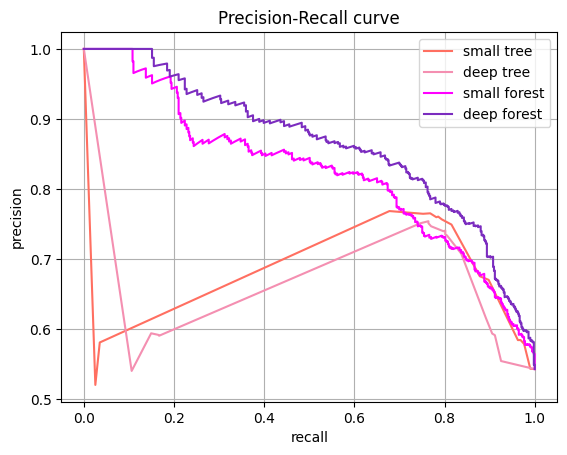

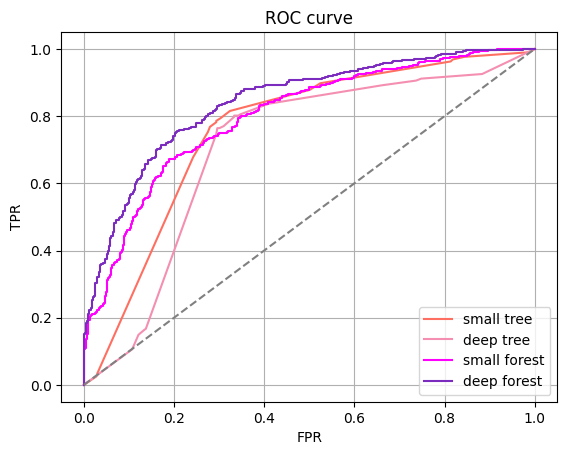

In [122]:
def calculate_pr_roc_curves(model, X_test, y_test):
    y_score = model.predict_proba(X_test)[:, 1]
    prec, rec, pr_thresholds = metrics.precision_recall_curve(y_test, y_score)
    fpr, tpr, roc_thresholds = metrics.roc_curve(y_test, y_score)
    return {"pr": [prec, rec, pr_thresholds],
            "roc": [fpr, tpr, roc_thresholds]}

small_tree_pr_roc = calculate_pr_roc_curves(small_tree, X_test, y_test)
deep_tree_pr_roc = calculate_pr_roc_curves(deep_tree, X_test, y_test)
small_forest_pr_roc = calculate_pr_roc_curves(small_forest, X_test, y_test)
deep_forest_pr_roc = calculate_pr_roc_curves(deep_forest, X_test, y_test)

# precision-recall curve
plt.figure()
plt.plot(small_tree_pr_roc["pr"][1], small_tree_pr_roc["pr"][0], label="small tree", color="#FF6F61")
plt.plot(deep_tree_pr_roc["pr"][1], deep_tree_pr_roc["pr"][0], label="deep tree", color="#F48FB1")
plt.plot(small_forest_pr_roc["pr"][1], small_forest_pr_roc["pr"][0], label="small forest", color="#FF00FF")
plt.plot(deep_forest_pr_roc["pr"][1], deep_forest_pr_roc["pr"][0], label="deep forest", color="#7B2CBF")
plt.xlabel("recall")
plt.ylabel("precision")
plt.title("Precision-Recall curve")
plt.legend(loc="upper right")
plt.grid()
plt.show()

# ROC curve
plt.figure()
plt.plot(small_tree_pr_roc["roc"][0], small_tree_pr_roc["roc"][1], label="small tree", color="#FF6F61")
plt.plot(deep_tree_pr_roc["roc"][0], deep_tree_pr_roc["roc"][1], label="deep tree", color="#F48FB1")
plt.plot(small_forest_pr_roc["roc"][0], small_forest_pr_roc["roc"][1], label="small forest", color="#FF00FF")
plt.plot(deep_forest_pr_roc["roc"][0], deep_forest_pr_roc["roc"][1], label="deep forest", color="#7B2CBF")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC curve")
plt.legend(loc="lower right")
plt.grid()
plt.show()

# Deep forest with higher recall

Investigated two methods to achieve a recall above 0.95:
1. increasing the weight of the positive class during training
2. lowering the classification threshold

In [123]:
# experimenting with classes weights
X_train_new, X_val, y_train_new, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

deep_forest_new_weights = RandomForestClassifier(max_depth=10, random_state=42, n_estimators=50, criterion='gini', class_weight={0:1, 1:5})
deep_forest_new_weights.fit(X_train_new, y_train_new)

deep_forest_new_weights_metrics = calculate_metrics(deep_forest_new_weights, X_test, y_test)
print(f"Precision: {deep_forest_new_weights_metrics['precision']:.4f}\nRecall: {deep_forest_new_weights_metrics['recall']:.4f}\nAccuracy: {deep_forest_new_weights_metrics['acc']:.4f}\nF1: {deep_forest_new_weights_metrics['f1']:.4f}\nLog loss: {deep_forest_new_weights_metrics['log_loss']:.4f}")

Precision: 0.5806
Recall: 0.9902
Accuracy: 0.6066
F1: 0.7320
Log loss: 0.6804


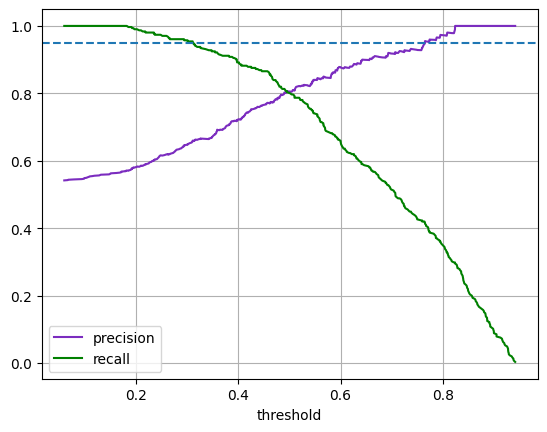

True
Best threshold: 0.311215
Precision:      0.6599
Recall:         0.9541

Metrics on validation set:
Precision: 0.6599
Recall: 0.9541
Accuracy: 0.7087
F1: 0.7802
Log loss: 0.4805

Metrics on test set:
Precision: 0.6403
Recall: 0.9548
Accuracy: 0.6844
F1: 0.7666
Log loss: 0.5020


In [124]:
# adjusting threshold
deep_forest_new_thres = RandomForestClassifier(max_depth=10, random_state=42, n_estimators=50, criterion='gini')
deep_forest_new_thres.fit(X_train_new, y_train_new)
y_score = deep_forest_new_thres.predict_proba(X_val)[:, 1]
prec, rec, pr_thresholds = metrics.precision_recall_curve(y_val, y_score)

plt.figure()
plt.plot(pr_thresholds, prec[:-1], label="precision", color="#7B2CBF")
plt.plot(pr_thresholds, rec[:-1], label="recall", color='green')
plt.axhline(y=0.95, linestyle="--")
plt.xlabel("threshold")
plt.legend(loc="best")
plt.grid()
plt.show()

# find optimal threshold
prec = prec[:-1]
rec = rec[:-1]

mask = rec > 0.95
print(np.any(mask))

valid_prec = prec[mask]
valid_rec = rec[mask]
valid_thresholds = pr_thresholds[mask]
best_idx = np.argmax(valid_prec)
best_threshold = valid_thresholds[best_idx]
best_prec = valid_prec[best_idx]
best_rec = valid_rec[best_idx]

print(f"Best threshold: {best_threshold:.6f}")
print(f"Precision:      {best_prec:.4f}")
print(f"Recall:         {best_rec:.4f}")

# check on val and test set
deep_forest_new_thres_metrics_val = calculate_metrics(deep_forest_new_thres, X_val, y_val, threshold=best_threshold)

print(f"\nMetrics on validation set:\nPrecision: {deep_forest_new_thres_metrics_val['precision']:.4f}\nRecall: {deep_forest_new_thres_metrics_val['recall']:.4f}\nAccuracy: {deep_forest_new_thres_metrics_val['acc']:.4f}\nF1: {deep_forest_new_thres_metrics_val['f1']:.4f}\nLog loss: {deep_forest_new_thres_metrics_val['log_loss']:.4f}")

deep_forest_new_thres_metrics_test = calculate_metrics(deep_forest_new_thres, X_test, y_test, threshold=best_threshold)

print(f"\nMetrics on test set:\nPrecision: {deep_forest_new_thres_metrics_test['precision']:.4f}\nRecall: {deep_forest_new_thres_metrics_test['recall']:.4f}\nAccuracy: {deep_forest_new_thres_metrics_test['acc']:.4f}\nF1: {deep_forest_new_thres_metrics_test['f1']:.4f}\nLog loss: {deep_forest_new_thres_metrics_test['log_loss']:.4f}")

# Conclusions


In [125]:
results = {
    "deep_forest (weights)": deep_forest_new_weights_metrics,
    "deep_forest (adjusted threshold)": deep_forest_new_thres_metrics_test,
    "deep_forest": deep_forest_metrics,
}

df_metrics = pd.DataFrame.from_dict(results, orient="index")
df_metrics.index.name = "model"
display(df_metrics)

,precision,recall,acc,f1,log_loss
model,,,,,
deep_forest (weights),0.580645,0.990177,0.606610,0.732026,0.680379
deep_forest (adjusted threshold),0.640316,0.954813,0.684435,0.766562,0.502005
deep_forest,0.772983,0.809430,0.767591,0.790787,0.505388


Both approaches achieved a recall above 0.95. However, threshold adjustment (2nd approach) provided a better balance between precision and recall, with higher accuracy and F1-score and lower log-loss than the 1st approach.